#### [HOME](../README.md) | [NEXT](1.raw_course_specification.ipynb)

---

# Object Oriented Paradigm in scikit-learn Machine Learning

This Jupyter Notebook will explore the `scikit-learn` library. However, the objective is not so much to learn about `scikit-learn`, but to explore how a professionally developed, widely used library uses the organizational principles of object oriented programming to provide a enhanced user experience.

The main theme of our explorations will be the power of **Providing a Consistent Interface**.  One of the fundamental benefits of OOP is the ability to program a simple interface that is a facade to a complex implementation. Sklearn is a very good example of this important programming philosophy.

Students should be able to identify OOP principals such as generalisation, inheritance, abstraction, polymorphism and encapsulation.

Students can look at the [scikit-learn source](https://github.com/scikit-learn/scikit-learn) to see these principals at the code level.

In [1]:
import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('ggplot')

from sklearn.linear_model import LinearRegression, LogisticRegression

## Regressors

In a Supervised Learning problem we have some data $X$ (often called the **features**) which we want to use to make a prediction of another measurement $y$ (often called the **target**).  For example:

  - Use the history of all board game ratings on [Board Game Geek](https://boardgamegeek.com/) ($X$) to predict the rating a user will give a new game ($y$).
  - Use the history of all customers of a car insurance company ($X$) to predict the likelihood of a new customer being involved in a car accident ($y$).
  - Predict which type of animal ($y$) appears in a black and white photo taken by a wildlife camera ($X$).
  - Predict whether a flight will be delayed and, if so, how delayed it will be.
  
The general theme is that:

> We **fit** a model to some data ($X, y$), and then use the model to **predict** given some new data.

Let's look at two examples.

### Regression: Linear Regression

Our first example is **linear regression**.  In linear regression we have feature data $X$, and our target response is a **continuous** measurement.

The data set we will use to demonstrate linear regression contains measurements on a single species of insect captured on two continents.

In [2]:
insects = pd.read_csv('./data/insects.csv', sep='\t')
insects.head()

,continent,latitude,wingsize,sex
0,1,35.5,901,0
1,1,37.0,896,0
2,1,38.6,906,0
3,1,40.7,907,0
4,1,40.9,898,0


Suppose we want to predict an insects wing size given the other measurements we have.  Since wing size is a continuous measurement, linear regression is an appropriate way to approach this problem.

All **regression objects** are used in the same way in sklearn.

1\. Create a regression object of the appropriate type.

In [3]:
insects_regression = LinearRegression()

To explain this further, `LinearRegression` is a **class**, and calling it `__init__`'s an **object** which is an **instance of the LinearRegression class**.

2\. Use the `fit` method on the regression object to train the model using your data.

In [4]:
X_insects = insects[['continent', 'latitude', 'sex']]
y_insects = insects['wingsize']
insects_regression.fit(X_insects, y_insects)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ -4.13, 1.79,-98.86]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['continent','latitude','sex']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,836.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


Above we trained a linear model to create an equation of the form:

$$ \text{WingSize} \approx a + b \times \text{Continent} + c \times \text{Latitude} + d \times \text{Sex} $$

When we used `fit`, the model used the data we supplied to compute the correct values of the numbers $a, b, c, d$.  We can now pull these numbers out of the model object.

In [5]:
print("a = {:2.2f}".format(insects_regression.intercept_))

a = 836.16


In [6]:
print("b, c, d = {}".format(insects_regression.coef_))

b, c, d = [ -4.12890383   1.79260932 -98.85714286]


3\. Use the `predict` method to compute predicted values your data (could be the data you used to train the model, or another dataset entirely.

In [7]:
wing_size_predictions = insects_regression.predict(X_insects)

In [8]:
print(wing_size_predictions[:10])

[895.67349147 898.36240545 901.23058036 904.99505993 905.35358179
 908.04249577 912.70328    915.92997677 919.51519541 921.30780472]


Calling the `predict` method uses the equation to make predictions about wing size.  This is very useful if we had data on insects that we **didn't** know the wingsize of. 

For fun, let's plot the true data and the predicted data in two scatterplots.

Text(0, 0.5, 'Predicted Wing Span')

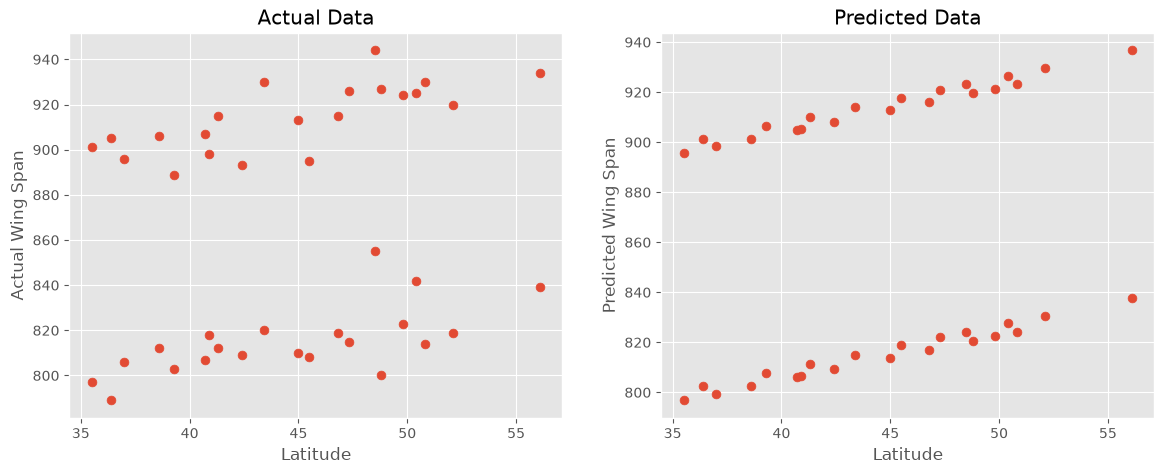

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

axs[0].scatter(insects.latitude, insects.wingsize, s=40)
axs[0].set_title("Actual Data")
axs[0].set_xlabel("Latitude")
axs[0].set_ylabel("Actual Wing Span")


axs[1].scatter(insects.latitude, wing_size_predictions, s=40)
axs[1].set_title("Predicted Data")
axs[1].set_xlabel("Latitude")
axs[1].set_ylabel("Predicted Wing Span")

**Summary:** A `LinearRegression` uses the methods `fit` and `predict` to adapt itself to data, and to then make predictions.

### Classification: Logistic Regression

Our second example is **logistic regression**.  In logistic regression we have feature data $X$, and our target $y$ is a **binary** measurement.

A **binary** measurement can only take two values, which are traditionally labeled as $0$ and $1$.

Our example will use a dataset of wells in Bangladesh.  Many family wells are contaminated with arsenic; a team of scientists visited and measured:

  - The arsenic levels in each family's well.
  - The distance to the nearest safe well.
  - The level of education of the household.
  - The household's involvement in the community.
  
After discussing the level of arsenic with each family, the families with unsafe levels of arsenic were advised to switch to a nearby safe well.  Years later, the team followed up, and measured which families switched wells.

In [10]:
wells = pd.read_csv('./data/wells.dat', sep=' ')

In [11]:
wells.head()

,id,switch,arsenic,dist,assoc,educ
0,1,1,2.36,16.826000,0,0
1,2,1,0.71,47.321999,0,0
2,3,0,2.07,20.966999,0,10
3,4,1,1.15,21.486000,0,12
4,5,1,1.10,40.874001,1,14


We can use a logistic regression to predict whether a family will switch based on the other data the team measured.

The first step is to `__init__` an instance (or object) of the `LogisticRegression` class.

In [12]:
wells_regression = LogisticRegression()

We can use the `fit` method of the `LogisticRegression` class to train the model using our data.

In [13]:
# We don't need the i'd column, so drop it.
X_wells_names = np.array(['arsenic', 'dist', 'assoc', 'educ'])
X_wells = wells[X_wells_names]
# The response is already encoded as 0's, and 1's.
y_wells = wells['switch']
wells_regression.fit(X_wells, y_wells)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

Now that the regression has been fit, we can use the `predict` method to forecast whether our model thinks a family will switch wells.

In [14]:
wells_predictions = wells_regression.predict(X_wells)
print(wells_predictions[:10])

[1 0 1 1 1 1 1 1 1 1]


Additionally (and in many cases more usefully), the `LogisticRegression` has a `predict_proba` method that produces a predicted **probability** that a family will switch well.

In [15]:
wells_probabilities = wells_regression.predict_proba(X_wells)
print(wells_probabilities[:10])

[[0.311407   0.688593  ]
 [0.5618803  0.4381197 ]
 [0.26006313 0.73993687]
 [0.33248748 0.66751252]
 [0.38667832 0.61332168]
 [0.21450595 0.78549405]
 [0.36540595 0.63459405]
 [0.21669702 0.78330298]
 [0.31473513 0.68526487]
 [0.44449671 0.55550329]]


The `predict_proba` method creates a two column array, the first is the probability the family will not switch, the second is the probability they will.  This means that the rows of this matrix always add to $1$.

In [16]:
np.sum(wells_probabilities, axis=1)

array([1., 1., 1., ..., 1., 1., 1.], shape=(3020,))

We can use the `predict_proba` method to plot the actual data, along with the predicted probabilities that a family will switch.

Text(0, 0.5, 'Probability of Switching')

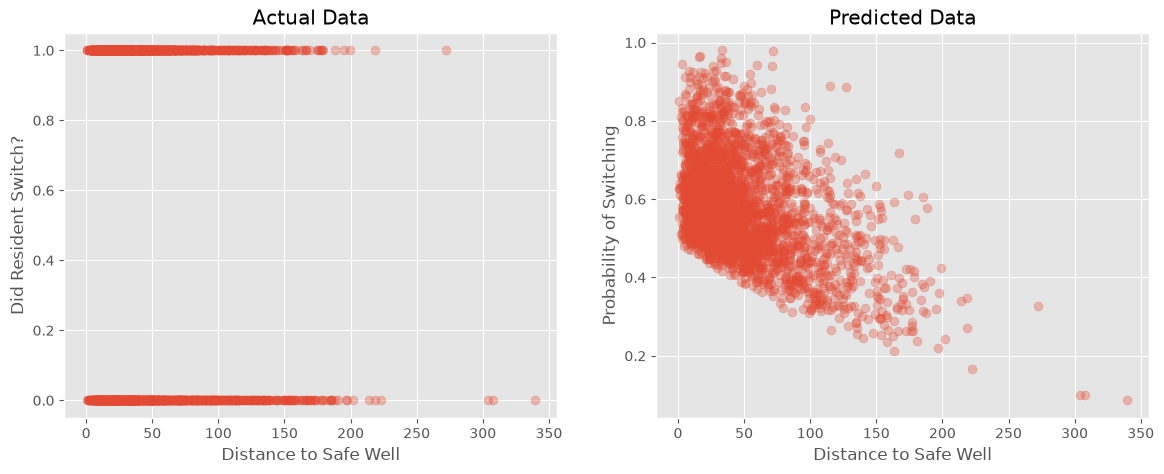

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

axs[0].scatter(wells.dist, wells.switch, s=40, alpha=0.33)
axs[0].set_title("Actual Data")
axs[0].set_xlabel("Distance to Safe Well")
axs[0].set_ylabel("Did Resident Switch?")


axs[1].scatter(wells.dist, wells_probabilities[:, 1], s=40, alpha=0.33)
axs[1].set_title("Predicted Data")
axs[1].set_xlabel("Distance to Safe Well")
axs[1].set_ylabel("Probability of Switching")

### Bring them back together

The two regression classes `LinearRegression` and `LogisticRegression` both inherit supper classes from the same `_base` which has generalised many of the core functionality of the two subclasses and thus have many overriding polymorphic methods in common:

  - Both have a `fit` methods.  The `fit` methods for both take the same arguments `X` and `y`.
  - Both have a `predict` method.  The `predict` methods for both take the same argument, `X`.
  
We can summarize this by saying that **`LinearRegression` and `LogisticRegression` have the same interface**.  They have the same methods that are used to the same conceptual tasks.  This allows us to write code that performs high level tasks using the `fit` and `predict` methods, which can then be used with any object that implements both `fit` and `predict` methods.